# Project 1: Student Performance

---

### Dataset: Student Performance

The dataset explores how well students performed in secondary education (high school) in two Portuguese schools. The dataset used student reports and questionaires for two different grades: Math and Portuguese language.

Data Source: P. Cortez, A. M. G. Silva. 2008

Documentation: [link text](https://archive.ics.uci.edu/dataset/320/student+performance$0)

### Research Question

Can we identify variables can acurrately predict how well students perform in a math class, and if so, which is the most influential and more consistent predictor?

This question is important to us as education is a key compenent in someones life when determining how succesful they will be and maximizing peoples success in education tends to lead to better quality of living on and individual and societal level


### Implementing our dataset and setting up our libraries

---

In [ ]:
# Import our essential libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder, OrdinalEncoder
from sklearn.model_selection import train_test_split

# Set up plotting
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)


In [ ]:


# Paste your copied raw GitHub URL here
url = 'https://raw.githubusercontent.com/kbarrera5-source/studentprojectfile/refs/heads/main/student-mat%20-%20student-mat.csv'

# Load the CSV file into a DataFrame
student_performance = pd.read_csv(url)

# Preview the data
student_performance.head()


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## Data reconciliation

Initial concerns for whether or not the grade distribution of the two schools were different due to sample size differences led us to compare them.

/tmp/ipykernel_488/3146962941.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gabriel_school['letter grades'] = pd.Categorical(gabriel_school['letter grades'], categories=grade_order, ordered=True)
/tmp/ipykernel_488/3146962941.py:32: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  moushino_school['letter grades'] = pd.Categorical(moushino_school['letter grades'], categories=grade_order, ordered=True)


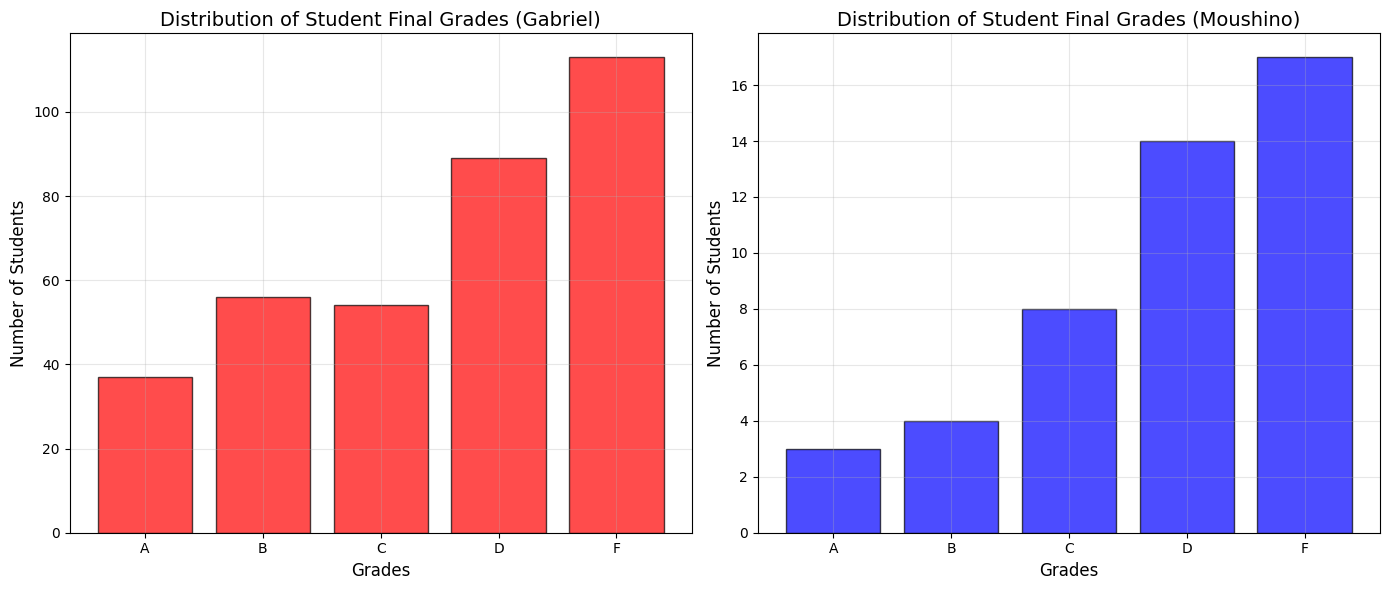

In [ ]:
## plotting the letter grades from the two different schools


# Create a copy of the dataset
student_performance_copy = student_performance.copy()

# Adding 'letter grades' to student_performance_copy so we can isolate pass_students safely  (F)
student_performance_copy = student_performance_copy.copy()
student_performance_copy.loc[student_performance_copy['G3'].between(0, 9), 'letter grades'] = 'F'
student_performance_copy.loc[student_performance_copy['G3'].between(10, 11), 'letter grades'] = 'D'
student_performance_copy.loc[student_performance_copy['G3'].between(12, 13), 'letter grades'] = 'C'
student_performance_copy.loc[student_performance_copy['G3'].between(14, 15), 'letter grades'] = 'B'
student_performance_copy.loc[student_performance_copy['G3'].between(16, 20), 'letter grades'] = 'A'

# Split into groups based on the 'school' feature
gabriel_school = student_performance_copy[student_performance_copy['school'] == 'GP']
moushino_school = student_performance_copy[student_performance_copy['school'] == 'MS']

# Define the correct chronological academic order
grade_order = ['A', 'B', 'C', 'D', 'F']

pass_students = student_performance_copy[
    (student_performance_copy['letter grades'].isin(['A', 'B', 'C']))
]

fail_students = student_performance_copy[
    (student_performance_copy['letter grades'].isin(['D', 'F']))
]

# Convert 'letter grades' to an ordered Categorical type so plots order them correctly
gabriel_school['letter grades'] = pd.Categorical(gabriel_school['letter grades'], categories=grade_order, ordered=True)
moushino_school['letter grades'] = pd.Categorical(moushino_school['letter grades'], categories=grade_order, ordered=True)

# Set up the subplot layout
plt.figure(figsize=(14, 6))

# Plot Gabriel School
plt.subplot(1, 2, 1)
gabriel_counts = gabriel_school['letter grades'].value_counts().reindex(grade_order)
plt.bar(gabriel_counts.index, gabriel_counts.values, color='red', alpha=0.7, edgecolor='black')
plt.title('Distribution of Student Final Grades (Gabriel)', fontsize=14)
plt.xlabel('Grades', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.grid(True, alpha=0.3)

# Plot Moushino School
plt.subplot(1, 2, 2)
moushino_counts = moushino_school['letter grades'].value_counts().reindex(grade_order)
plt.bar(moushino_counts.index, moushino_counts.values, color='blue', alpha=0.7, edgecolor='black')
plt.title('Distribution of Student Final Grades (Moushino)', fontsize=14)
plt.xlabel('Grades', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

The distribution of the two schools grades are roughly the same so we decided to treat them as one cohort

##Analysis

**For context grading scale of school system is 0-20 translation to standard american grading is:
between(0, 9) = 'F'
between(10, 11) = 'D'
between(12, 13) = 'C'
between(14, 15) = 'B'
between(16, 20)= 'A'
**

What grading period has the most leverage on the final grade?

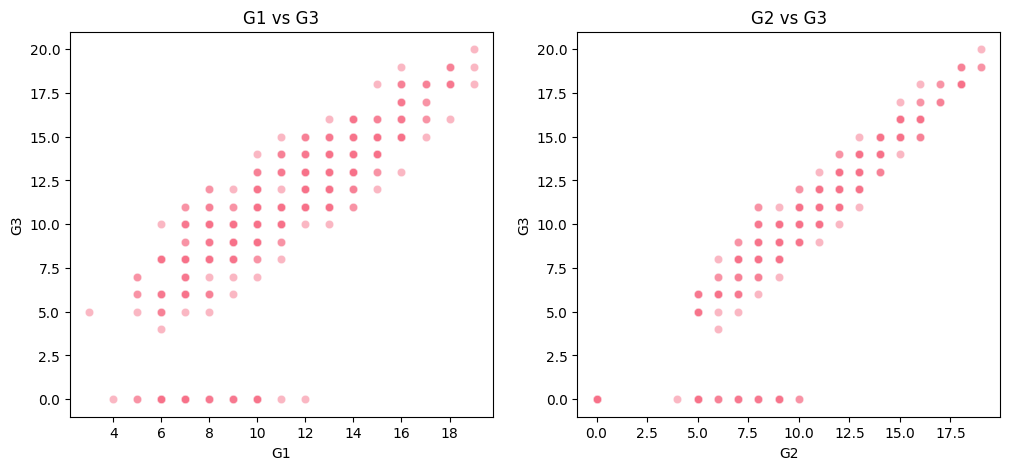

In [ ]:
#check G1 G2 G3 relation
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=student_performance_copy, x='G1', y='G3', alpha=0.5, ax=axes[0])
axes[0].set_title('G1 vs G3')

sns.scatterplot(data=student_performance_copy, x='G2', y='G3', alpha=0.5, ax=axes[1])
axes[1].set_title('G2 vs G3')

plt.show()



In [ ]:
#Correlation between G1, G2, G3
data_clean = student_performance_copy[student_performance_copy['G3'] > 0]
print(data_clean[['G1', 'G2', 'G3']].corr())

          G1        G2        G3
G1  1.000000  0.901940  0.891805
G2  0.901940  1.000000  0.965583
G3  0.891805  0.965583  1.000000


In [ ]:
# The three grades are very strongly related.
# Every pair is 0.89 or higher. Students who score
# well in one period score well in the others, and the
# same is true of low scorers.
# G2 and G3 (0.966) are more tightly linked than G1 and G3 (0.892).
# The most recent grade is the best predictor of the next one, which
# is why G2 alone predicts G3 so well

How much does outside of school support influences G scores?

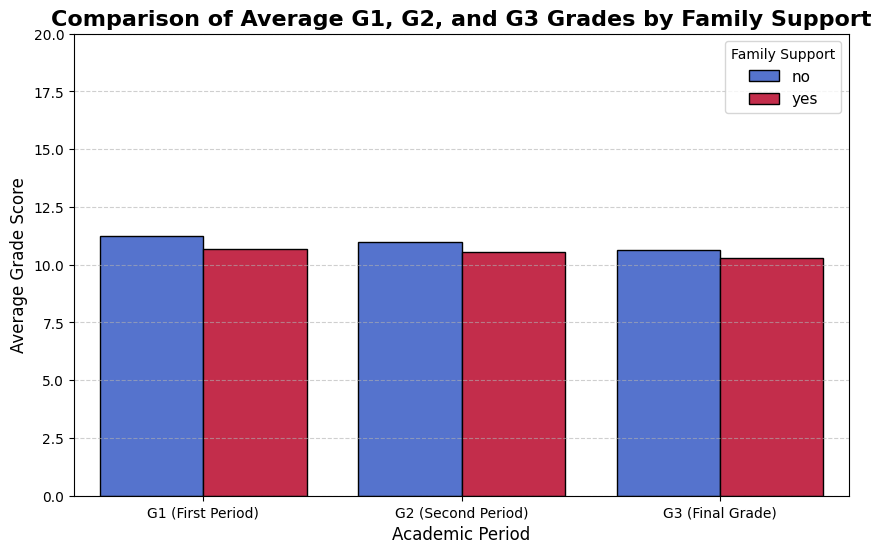

In [ ]:
plt.figure(figsize=(10, 6))

# Calculate the mean scores grouped by family support
grade_means = student_performance.groupby('famsup')[['G1', 'G2', 'G3']].mean().reset_index()

# Reshape the data so 'G1', 'G2', 'G3' become a single sequential column
grade_means_melted = grade_means.melt(
    id_vars='famsup',
    value_vars=['G1', 'G2', 'G3'],
    var_name='Period',
    value_name='Average_Grade'
)


period_map = {'G1': 'G1 (First Period)', 'G2': 'G2 (Second Period)', 'G3': 'G3 (Final Grade)'}
grade_means_melted['Period'] = grade_means_melted['Period'].map(period_map)

# Plot as a grouped bar chart
sns.barplot(
    data=grade_means_melted,
    x='Period',
    y='Average_Grade',
    hue='famsup',
    palette={'yes': 'crimson', 'no': 'royalblue'},
    edgecolor='black'
)


plt.title('Comparison of Average G1, G2, and G3 Grades by Family Support', fontsize=16, fontweight='bold')
plt.xlabel('Academic Period', fontsize=12)
plt.ylabel('Average Grade Score', fontsize=12)
plt.ylim(0, 20)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title='Family Support', fontsize=11)
plt.show()

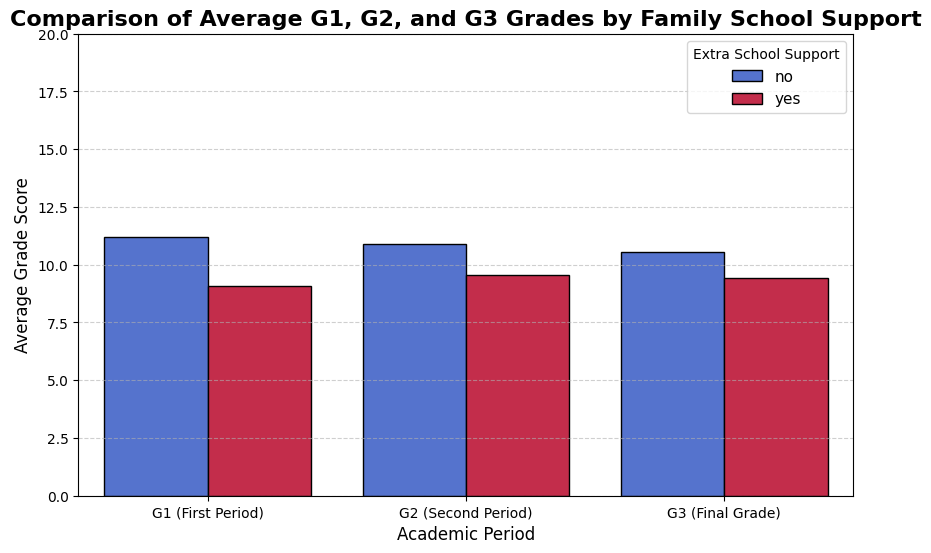

In [ ]:
plt.figure(figsize=(10, 6))

# Calculate the mean scores grouped by extra school support
grade_means = student_performance.groupby('schoolsup')[['G1', 'G2', 'G3']].mean().reset_index()

# Reshape the data so 'G1', 'G2', 'G3' become a single sequential column
grade_means_melted = grade_means.melt(
    id_vars='schoolsup',
    value_vars=['G1', 'G2', 'G3'],
    var_name='Period',
    value_name='Average_Grade'
)


period_map = {'G1': 'G1 (First Period)', 'G2': 'G2 (Second Period)', 'G3': 'G3 (Final Grade)'}
grade_means_melted['Period'] = grade_means_melted['Period'].map(period_map)

# Plot as a grouped bar chart
sns.barplot(
    data=grade_means_melted,
    x='Period',
    y='Average_Grade',
    hue='schoolsup',
    palette={'yes': 'crimson', 'no': 'royalblue'},
    edgecolor='black'
)


plt.title('Comparison of Average G1, G2, and G3 Grades by Family School Support', fontsize=16, fontweight='bold')
plt.xlabel('Academic Period', fontsize=12)
plt.ylabel('Average Grade Score', fontsize=12)
plt.ylim(0, 20)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title='Extra School Support', fontsize=11)
plt.show()

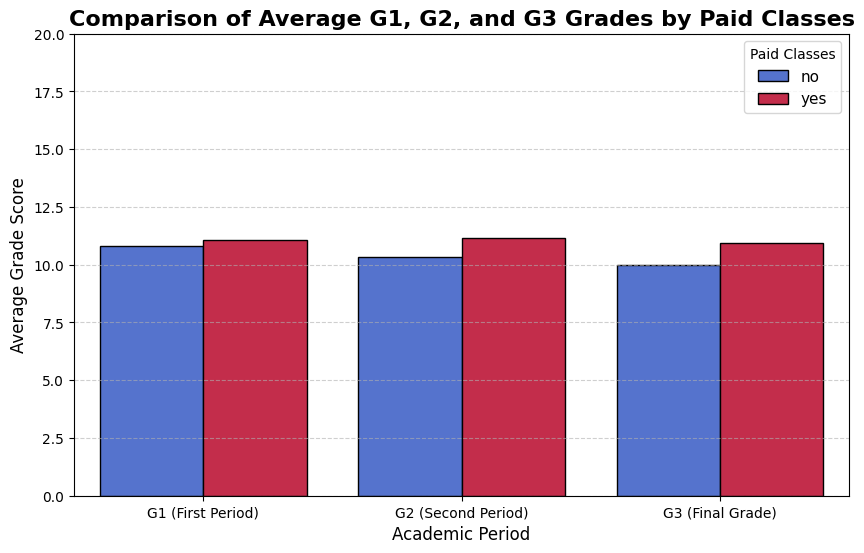

In [ ]:
plt.figure(figsize=(10, 6))

# Calculate the mean scores grouped by paid classes
grade_means = student_performance.groupby('paid')[['G1', 'G2', 'G3']].mean().reset_index()

# Reshape the data so 'G1', 'G2', 'G3' become a single sequential column
grade_means_melted = grade_means.melt(
    id_vars='paid',
    value_vars=['G1', 'G2', 'G3'],
    var_name='Period',
    value_name='Average_Grade'
)


period_map = {'G1': 'G1 (First Period)', 'G2': 'G2 (Second Period)', 'G3': 'G3 (Final Grade)'}
grade_means_melted['Period'] = grade_means_melted['Period'].map(period_map)

# Plot as a grouped bar chart
sns.barplot(
    data=grade_means_melted,
    x='Period',
    y='Average_Grade',
    hue='paid',
    palette={'yes': 'crimson', 'no': 'royalblue'},
    edgecolor='black'
)


plt.title('Comparison of Average G1, G2, and G3 Grades by Paid Classes', fontsize=16, fontweight='bold')
plt.xlabel('Academic Period', fontsize=12)
plt.ylabel('Average Grade Score', fontsize=12)
plt.ylim(0, 20)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title='Paid Classes', fontsize=11)
plt.show()

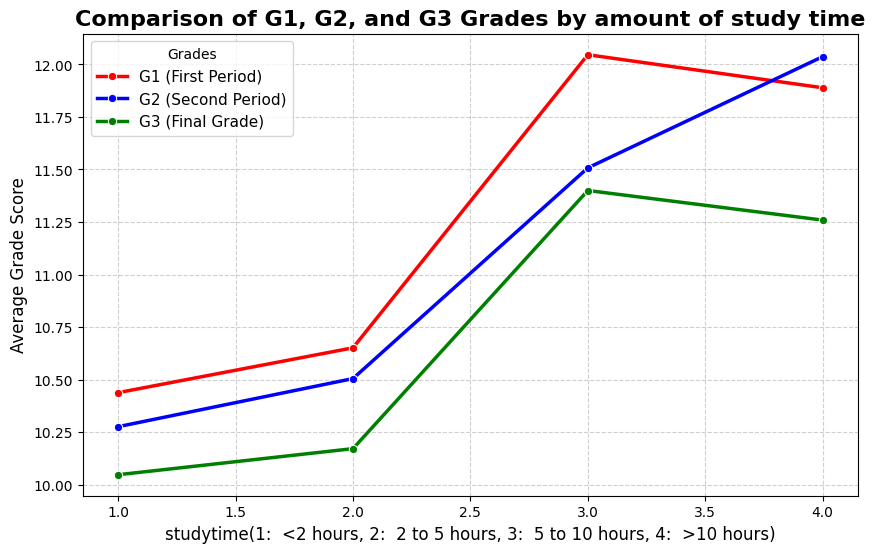

In [ ]:
plt.figure(figsize=(10, 6))

# Calculate the mean scores of G1, G2, and G3 grouped by study variable
grade_means = student_performance.groupby('studytime')[['G1', 'G2', 'G3']].mean().reset_index()

# Plot the trends for each grade
sns.lineplot(data=grade_means, x='studytime', y='G1', marker='o', linewidth=2.5, label='G1 (First Period)', color='red')
sns.lineplot(data=grade_means, x='studytime', y='G2', marker='o', linewidth=2.5, label='G2 (Second Period)', color='blue')
sns.lineplot(data=grade_means, x='studytime', y='G3', marker='o', linewidth=2.5, label='G3 (Final Grade)', color='green')

# Customize the chart
plt.title('Comparison of G1, G2, and G3 Grades by amount of study time', fontsize=16, fontweight='bold')
plt.xlabel('studytime(1:  <2 hours, 2:  2 to 5 hours, 3:  5 to 10 hours, 4:  >10 hours)', fontsize=12)
plt.ylabel('Average Grade Score', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Grades', fontsize=11)
plt.show()

Above we see that family support and extra school support seem to have a negative impact on average grade scores while paid classes and studytime have a positive impact on average grade scores

Lets investigate outside of school factors and absences.

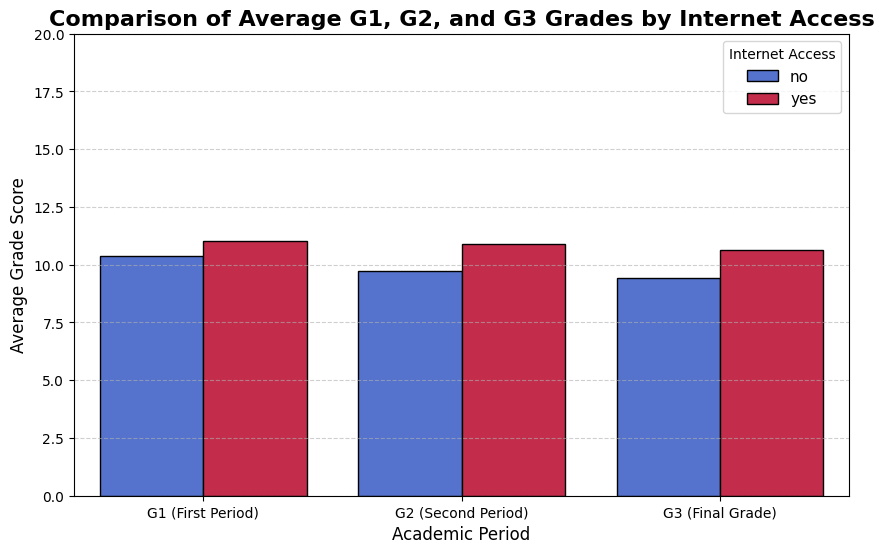

In [ ]:
plt.figure(figsize=(10, 6))

# Calculate the mean scores grouped by Access to Internet
grade_means = student_performance.groupby('internet')[['G1', 'G2', 'G3']].mean().reset_index()

# Reshape the data so 'G1', 'G2', 'G3' become a single sequential column
grade_means_melted = grade_means.melt(
    id_vars='internet',
    value_vars=['G1', 'G2', 'G3'],
    var_name='Period',
    value_name='Average_Grade'
)


period_map = {'G1': 'G1 (First Period)', 'G2': 'G2 (Second Period)', 'G3': 'G3 (Final Grade)'}
grade_means_melted['Period'] = grade_means_melted['Period'].map(period_map)

# Plot as a grouped bar chart
sns.barplot(
    data=grade_means_melted,
    x='Period',
    y='Average_Grade',
    hue='internet',
    palette={'yes': 'crimson', 'no': 'royalblue'},
    edgecolor='black'
)


plt.title('Comparison of Average G1, G2, and G3 Grades by Internet Access', fontsize=16, fontweight='bold')
plt.xlabel('Academic Period', fontsize=12)
plt.ylabel('Average Grade Score', fontsize=12)
plt.ylim(0, 20)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(title='Internet Access', fontsize=11)
plt.show()

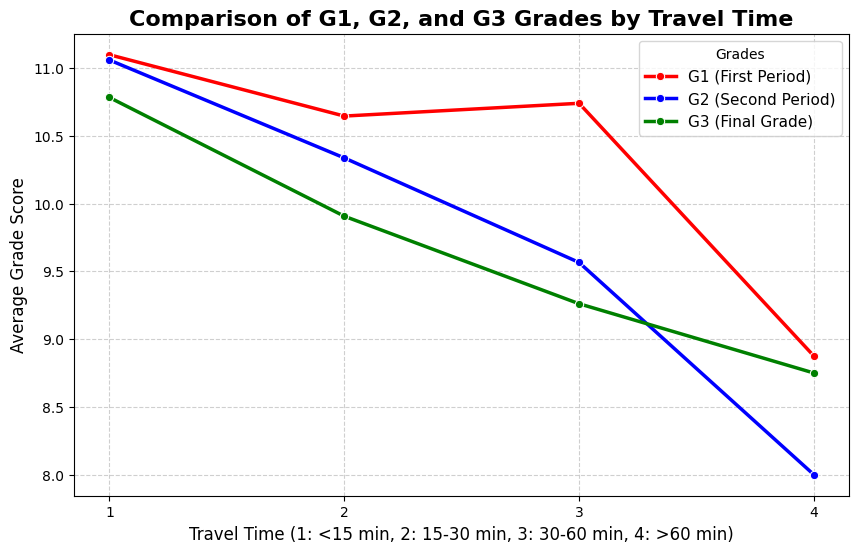

In [ ]:
plt.figure(figsize=(10, 6))

# Calculate the mean scores of G1, G2, and G3 grouped by traveltime
grade_means = student_performance.groupby('traveltime')[['G1', 'G2', 'G3']].mean().reset_index()

# Plot the trends for each grade
sns.lineplot(data=grade_means, x='traveltime', y='G1', marker='o', linewidth=2.5, label='G1 (First Period)', color='red')
sns.lineplot(data=grade_means, x='traveltime', y='G2', marker='o', linewidth=2.5, label='G2 (Second Period)', color='blue')
sns.lineplot(data=grade_means, x='traveltime', y='G3', marker='o', linewidth=2.5, label='G3 (Final Grade)', color='green')

# Customize the chart
plt.title('Comparison of G1, G2, and G3 Grades by Travel Time', fontsize=16, fontweight='bold')
plt.xlabel('Travel Time (1: <15 min, 2: 15-30 min, 3: 30-60 min, 4: >60 min)', fontsize=12)
plt.ylabel('Average Grade Score', fontsize=12)
plt.xticks([1, 2, 3, 4])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Grades', fontsize=11)
plt.show()

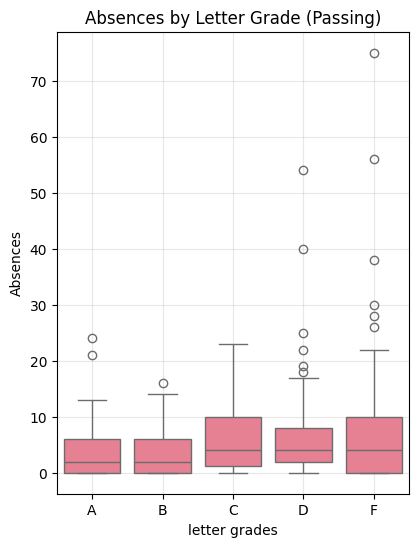

In [ ]:
## creating a boxplot to look at the students who received passing grades and failing grades and compare their absences (F)

plt.subplot(1, 2, 1)
sns.boxplot(data=student_performance_copy, x='letter grades', y='absences', order=['A', 'B', 'C', 'D', 'F'], legend=False)
plt.title('Absences by Letter Grade (Passing)')
plt.ylabel('Absences')
plt.grid(True, alpha=0.3)

We see that the differences are slight but there is a trend here things that make it harder to get to school or access school resources and or not going to school lower the average grade of students

We also wanted to investigate how much past failures influenced grades as seen below past failures seem to have a negative impact on grades across the two periods and the final grade

=== Top 5 Non-Grade Numerical Correlates with G3 ===
failures   -0.360415
Medu        0.217147
age        -0.161579
Fedu        0.152457
goout      -0.132791
Name: G3, dtype: float64


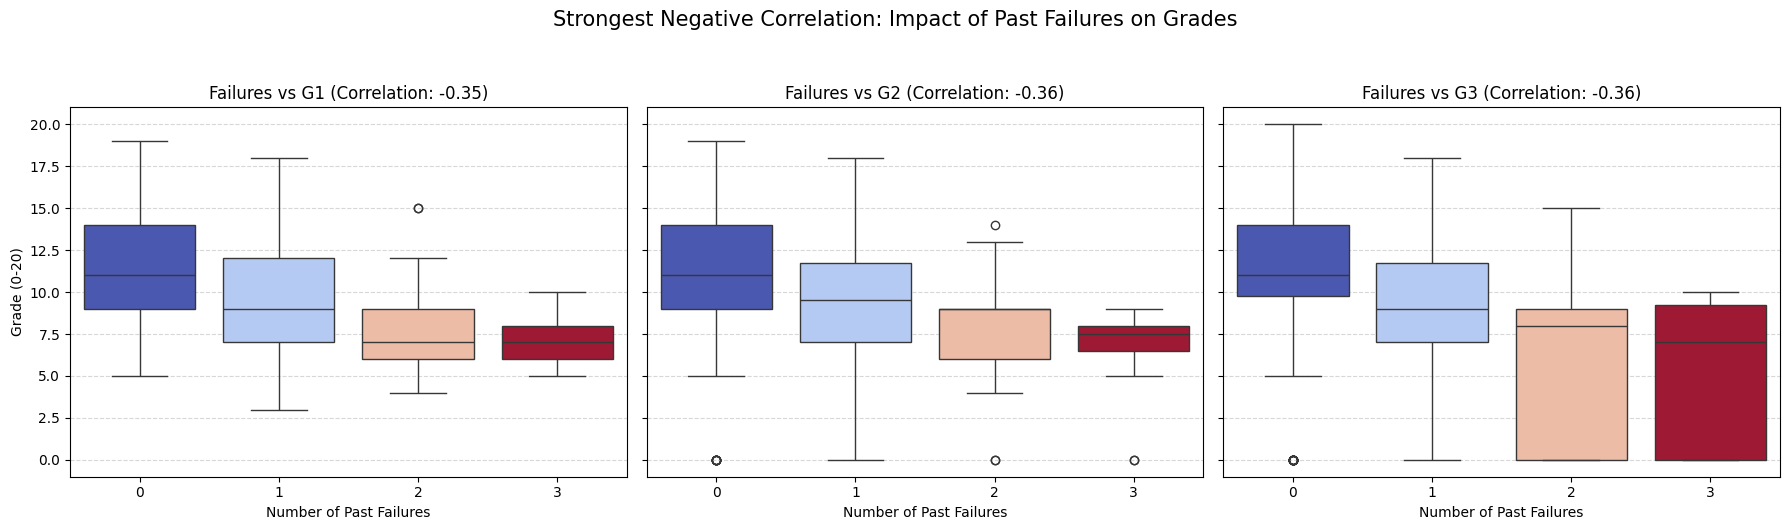

In [ ]:


# 1. Use the dataset already loaded in your workspace
try:
    df_mat = student_performance
except NameError:
    # Fallback to load from url if student_performance isn't found
    url = 'https://raw.githubusercontent.com/kbarrera5-source/studentprojectfile/refs/heads/main/student-mat%20-%20student-mat.csv'
    df_mat = pd.read_csv(url)

# 2. Identify numerical columns to check for correlation
numeric_cols = df_mat.select_dtypes(include=['int64', 'float64']).columns

# 3. Compute correlation matrix and isolate correlations with G1, G2, and G3
correlations = df_mat[numeric_cols].corr()

print("=== Top 5 Non-Grade Numerical Correlates with G3 ===")
# Exclude G1, G2, G3, and letter grades from the ranking
non_grade_corr = correlations['G3'].drop(['G1', 'G2', 'G3', 'G_average'], errors='ignore')
print(non_grade_corr.reindex(non_grade_corr.abs().sort_values(ascending=False).index).head(5))

# 4. Plot 'failures' vs G1, G2, and G3 since it is the strongest predictor
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
grade_periods = ['G1', 'G2', 'G3']

for i, grade in enumerate(grade_periods):
    sns.boxplot(
        ax=axes[i],
        data=df_mat,
        x='failures',
        y=grade,
        palette='coolwarm',
        hue='failures',
        legend=False
    )
    # Get the correlation score directly from the correlations matrix
    corr_val = correlations.loc['failures', grade]
    axes[i].set_title(f"Failures vs {grade} (Correlation: {corr_val:.2f})", fontsize=12)
    axes[i].set_xlabel("Number of Past Failures", fontsize=10)
    axes[i].set_ylabel("Grade (0-20)" if i == 0 else "", fontsize=10)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

plt.suptitle("Strongest Negative Correlation: Impact of Past Failures on Grades", fontsize=15, y=1.05)
plt.tight_layout()
plt.show()

Below we see that the difference of

Students with Low Parent Education: 135
Students Seeking Higher Education: 123

Letter Grades:
letter grades
F    47
D    38
C    20
B    13
A     5
Name: count, dtype: int64


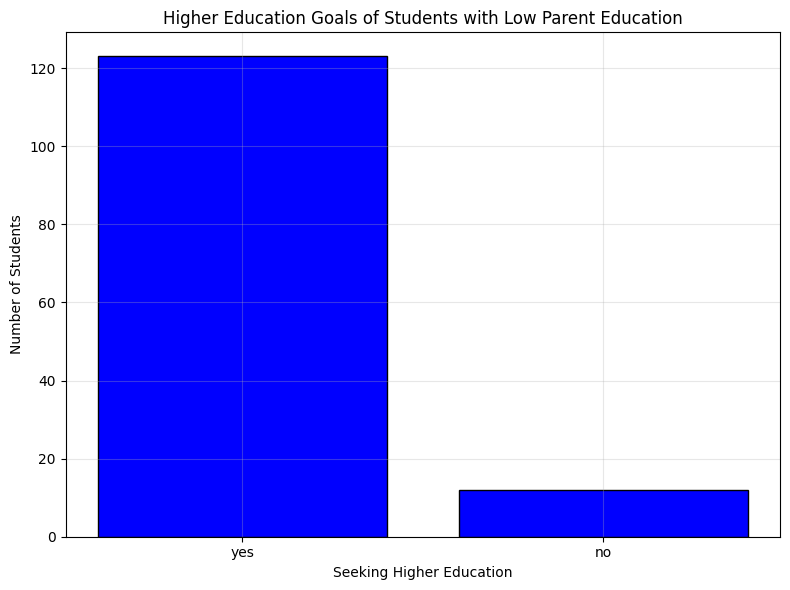

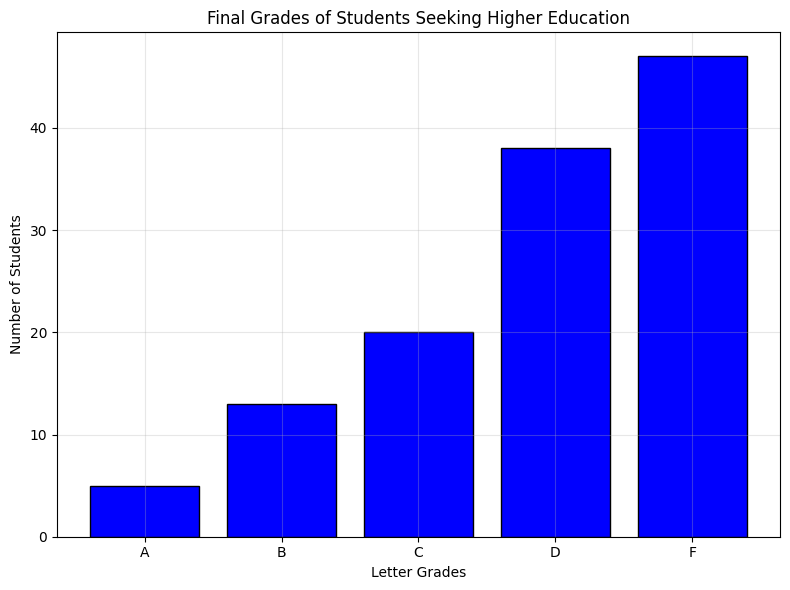

In [ ]:

# Map letter grades directly in the student_performance dataframe to resolve the KeyError
student_performance = student_performance.copy()
student_performance.loc[student_performance['G3'].between(0, 9), 'letter grades'] = 'F'
student_performance.loc[student_performance['G3'].between(10, 11), 'letter grades'] = 'D'
student_performance.loc[student_performance['G3'].between(12, 13), 'letter grades'] = 'C'
student_performance.loc[student_performance['G3'].between(14, 15), 'letter grades'] = 'B'
student_performance.loc[student_performance['G3'].between(16, 20), 'letter grades'] = 'A'

# Isolate students whose both parents have education levels below 3
low_education = student_performance[
    (student_performance['Medu'] < 3) &
    (student_performance['Fedu'] < 3)
]

# Isolate students who want higher education
higher_education = low_education[
    low_education['higher'] == 'yes'
]

# Count students
print("Students with Low Parent Education:",
      len(low_education))

print("Students Seeking Higher Education:",
      len(higher_education))

# Show their letter grades
print("\nLetter Grades:")
print(higher_education['letter grades'].value_counts())


# Graph 1: Students seeking higher education

plt.figure(figsize=(8, 6))

higher_counts = low_education['higher'].value_counts().reindex(
    ['yes', 'no'], fill_value=0)

plt.bar(higher_counts.index, higher_counts.values,
        color='blue', edgecolor='black')

plt.title('Higher Education Goals of Students with Low Parent Education')
plt.xlabel('Seeking Higher Education')
plt.ylabel('Number of Students')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Graph 2: Letter grades of students seeking higher education

grade_order = ['A', 'B', 'C', 'D', 'F']

plt.figure(figsize=(8, 6))

grade_counts = higher_education['letter grades'].value_counts().reindex(
    grade_order, fill_value=0)

plt.bar(grade_counts.index, grade_counts.values,
        color='blue', edgecolor='black')

plt.title('Final Grades of Students Seeking Higher Education')
plt.xlabel('Letter Grades')
plt.ylabel('Number of Students')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Below we investigte the distrubtion of parents education level based on students having a passing or failing grade. We noticed that students with a passing grade have a skewed distrubution of parental education where those who pass have a higher concestration of parents who went to college or beyond. Studetns with a failing grade have a higher concentration of parents who either only went to high school or somewhere between 5th and 9th grade.

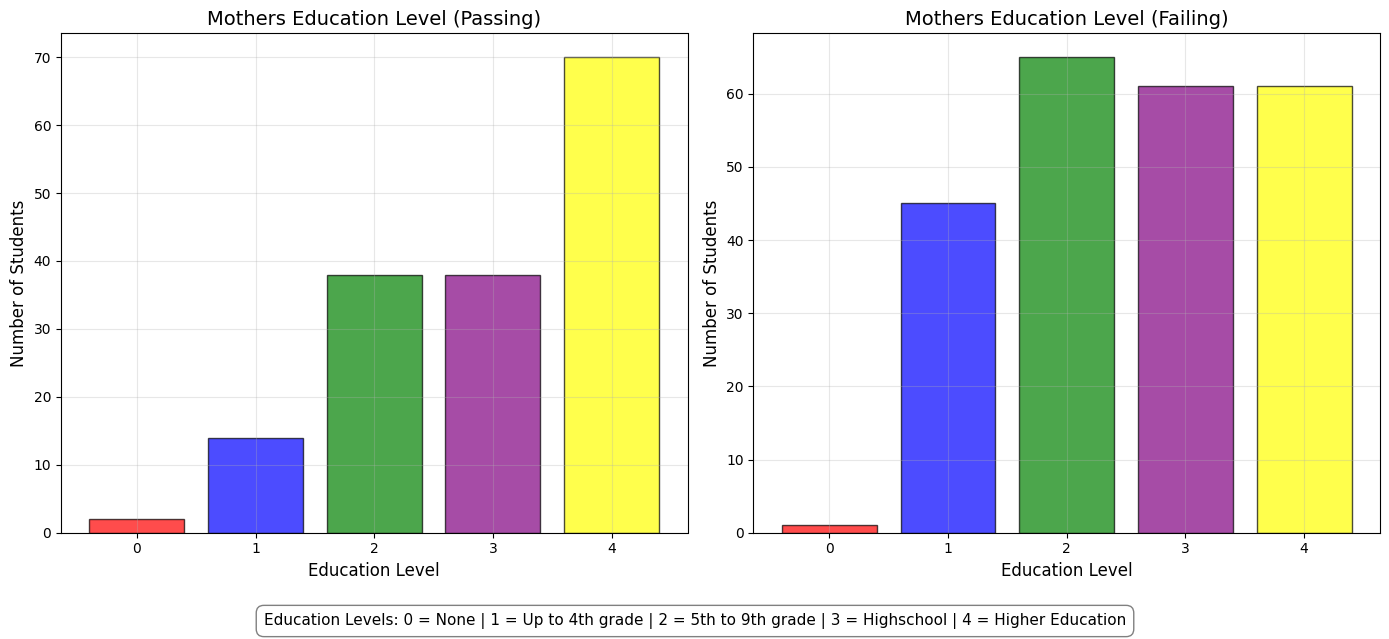

In [ ]:
## creating a bar chart to look at the passing and failing students and their mother's education level

# Set up a single figure for both side-by-side subplots
plt.figure(figsize=(14, 6))

# Plot passing grades
plt.subplot(1, 2, 1)
pass_counts = pass_students['Medu'].value_counts().sort_index()
colors = ['red', 'blue', 'green', 'purple', 'yellow']
plt.bar(pass_counts.index, pass_counts.values, color=colors, alpha=0.7, edgecolor='black')
plt.title('Mothers Education Level (Passing)', fontsize=14)
plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.grid(True, alpha=0.3)

# Plot failing grades
plt.subplot(1, 2, 2)
fail_counts = fail_students['Medu'].value_counts().sort_index()
plt.bar(fail_counts.index, fail_counts.values, color=colors, alpha=0.7, edgecolor='black')
plt.title('Mothers Education Level (Failing)', fontsize=14)
plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.grid(True, alpha=0.3)

# legend
plt.figtext(0.5, -0.05, "Education Levels: 0 = None | 1 = Up to 4th grade | 2 = 5th to 9th grade | 3 = Highschool | 4 = Higher Education", ha="center", fontsize=11, bbox=dict(facecolor='none', edgecolor='gray', boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

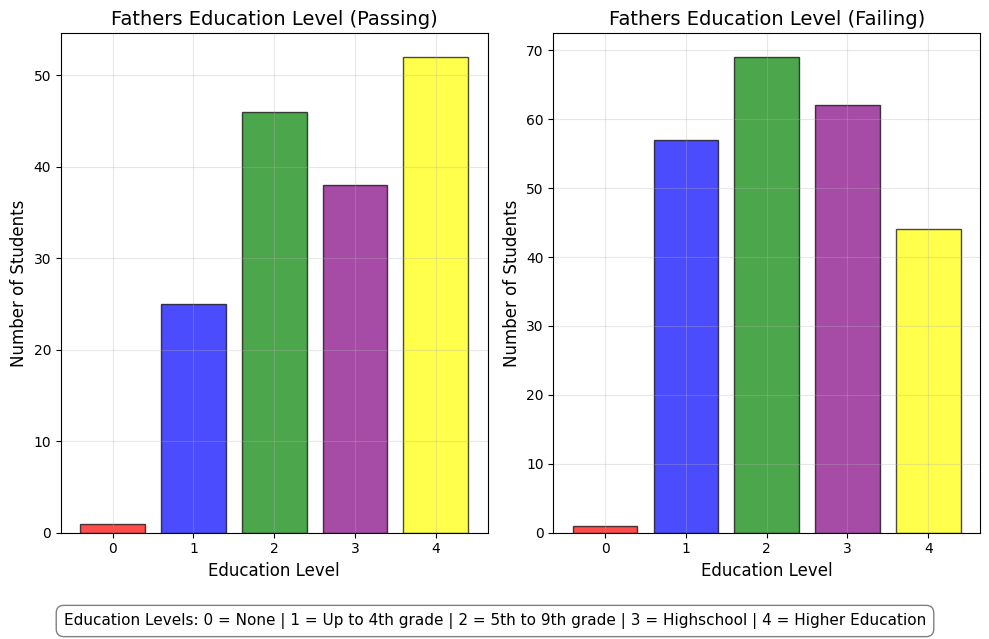

In [ ]:
## creating a bar chart to look at the passing and failing students and their father's education level

# Plot passing grades
plt.subplot(1, 2, 1)
pass_counts = pass_students['Fedu'].value_counts().sort_index()
colors = ['gray', 'blue', 'green', 'purple', 'orange']
plt.bar(pass_counts.index, pass_counts.values, color=['red', 'blue', 'green', 'purple', 'yellow'], alpha=0.7, edgecolor='black')
plt.title('Fathers Education Level (Passing)', fontsize=14)
plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.grid(True, alpha=0.3)

# Plot failing grades
plt.subplot(1, 2, 2)
fail_counts = fail_students['Fedu'].value_counts().sort_index()
colors = ['gray', 'blue', 'green', 'purple', 'orange']
plt.bar(fail_counts.index, fail_counts.values, color=['red', 'blue', 'green', 'purple', 'yellow'], alpha=0.7, edgecolor='black')
plt.title('Fathers Education Level (Failing)', fontsize=14)
plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Number of Students', fontsize=12)
plt.grid(True, alpha=0.3)
# legend
plt.figtext(0.5, -0.05, "Education Levels: 0 = None | 1 = Up to 4th grade | 2 = 5th to 9th grade | 3 = Highschool | 4 = Higher Education", ha="center", fontsize=11, bbox=dict(facecolor='none', edgecolor='gray', boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

##Conclusion

Based on the data we can see that this cohort has a large distribution of failing grades that can be predicted strongly with their second period score with this in mind we can make the prescription that we need to focus on this period of time the most for this group of students as this seems to be the time that makes determines the final grade. Outside support from family and the school itself seems to actually have a negative impact on performance; this may be due to a number of factors we can’t see from the data itself such as the quality of the school and families' extra support or the qualifications of the people giving the support. Paid classes on the other hand seem to marginally improve the average scores of students. Negative factors on the G scores are lots of absences, long travel time to and from school, lack of internet access, and past failures. There is also a trend that students who pass classes tend to have more educated parents past the high school level. We also see that students who want to pursue higher education have a similar distribution of grades to the rest of the group which implies that motivation is not the issue here. There is no one defining factor within this data set that solely influences the G scores of the students; rather it seems to be a culmination of factors that lower a student's performance in school. Things that can be improved are the quality of the extra tutoring provided at school as well as accommodations for the students to make the commute to school lower and to aim for a lower number of absences. Some things cannot be changed such as parents' education level or past failures of an individual student but that doesn’t mean we cannot provide more support to these kinds of students. This can be in the form of providing internet access to students and hiring more professionals to educate students who may be falling behind.

